# Inferência Bayesiana: Modelo Gaussiano vs. Modelo Robusto de Student-t

Este notebook explora a modelagem bayesiana de **dados contínuos** a partir de medições experimentais de deslocamentos químicos por Ressonância Magnética Nuclear (*NMR chemical shifts*) em proteínas, seguindo a abordagem do livro *Bayesian Analysis with Python*.

### Contexto Estatístico
1. **Modelo Normal (Gaussiano):** Assume que as observações seguem $Y_i \sim \mathcal{N}(\mu, \sigma^2)$. Embora a distribuição Normal seja fundamentada pelo Teorema Central do Limite e pelo princípio de Máxima Entropia (para variância finita conhecida), suas **caudas leves** ($\propto \exp(-y^2)$) tornam as estimativas de média ($\mu$) e desvio-padrão ($\sigma$) altamente sensíveis a **valores discrepantes (*outliers*)**.
2. **Modelo Robusto de Student-t:** Substitui a verossimilhança Normal pela distribuição **t de Student** $Y_i \sim \text{StudentT}(\nu, \mu, \sigma)$, introduzindo o parâmetro de graus de liberdade $\nu > 0$ (parâmetro de normalidade). Quando $\nu$ é pequeno, a distribuição possui **caudas pesadas** que absorvem *outliers* sem distorcer a estimativa da tendência central $\mu$ nem inflar a escala $\sigma$.

---

## 1. Importação das Bibliotecas
Carregamos as bibliotecas para manipulação de dados tabulares (`pandas`), computação científica (`numpy`), elicitação de distribuições (`preliz`), modelagem probabilística (`pymc`) e diagnóstico/visualização bayesiana (`arviz` e `arviz_plots`).

In [1]:

import pandas as pd
import pymc as pm
import numpy as np
import preliz as pz
import arviz as az
import arviz_plots.visuals as viz

## 2. Configuração Global de Estatísticas no ArviZ (`rcParams`)
Configuramos o ArviZ `1.x` para utilizar como padrão em todos os resumos e gráficos:
* **`stats.ci_kind = 'hdi'`:** Intervalo de Maior Densidade (*Highest Density Interval*), garantindo o menor intervalo que concentra a probabilidade desejada (essencial para parâmetros assimétricos como $\sigma$ e $\nu$).
* **`stats.ci_prob = 0.94`:** Intervalo de credibilidade de $94\%$.
* **`stats.point_estimate = 'mean'`:** Média *a posteriori* como estimativa pontual.

In [2]:
az.rcParams['stats.ci_kind'] = 'hdi'
az.rcParams['stats.ci_prob'] = 0.94
az.rcParams['stats.point_estimate'] = 'mean'

## 3. Semente Aleatória e Carregamento dos Dados
Definimos `np.random.seed(123)` para reprodutibilidade das operações numéricas.

In [3]:
np.random.seed(123)

### Carregamento do Dataset `chemical_shifts.csv`
Lemos a base de dados contendo $N = 47$ medições de deslocamentos químicos (em partes por milhão — ppm):
* **Resultado (`(47, 1)`):** $47$ observações univariadas contínuas. A maioria dos valores concentra-se entre $50$ e $56$, mas existem **duas medições atípicas (*outliers*)** acima de $60$ ppm.

In [4]:
data = pd.read_csv("https://raw.githubusercontent.com/aloctavodia/BAP3/refs/heads/main/code/data/chemical_shifts.csv")
data.shape

(47, 1)

## 4. Modelo 1: Inferência Gaussiana Padrão (`model`)
Especificamos um modelo Normal com dois parâmetros desconhecidos — a média populacional $\mu$ e o desvio-padrão $\sigma$:

$$\begin{aligned}
\mu &\sim \text{Uniforme}(40, 70) \\
\sigma &\sim \text{HalfNormal}(\sigma = 5) \\
Y_i \mid \mu, \sigma &\stackrel{\text{i.i.d.}}{\sim} \mathcal{N}(\mu, \sigma), \quad i = 1, \dots, 47
\end{aligned}$$

* **Justificativa das *Priors*:**
  * $\mu \sim \text{Uniforme}(40, 70)$: *Prior* pouco informativa cobrindo amplamente a faixa física plausível dos deslocamentos químicos.
  * $\sigma \sim \text{HalfNormal}(5)$: Como o desvio-padrão deve ser estritamente positivo ($\sigma > 0$), utilizamos uma distribuição Semi-Normal concentrada próxima de zero, mas permitindo dispersões moderadas.
* **Amostragem MCMC (`nutpie`):** O amostrador Hamiltoniano NUTS explora conjuntamente a superfície *a posteriori* bidimensional $P(\mu, \sigma \mid Y)$.

In [5]:
with pm.Model() as model:
    mu = pm.Uniform('mu', lower=40, upper=70)
    sigma = pm.HalfNormal('sigma', sigma=5)

    Y = pm.Normal('Y', mu=mu, sigma=sigma, observed=data)
    idata = pm.sample(nuts_sampler='nutpie', random_seed=4591)

NUTS[nutpie]: [mu, sigma]


Output()

### 4.1 Grafo Acíclico Direcionado (DAG) do Modelo Gaussiano
O diagrama gerado por `pm.model_to_graphviz(model)` mostra os dois nós estocásticos latentes no topo ($\mu \sim \text{Uniform}$ e $\sigma \sim \text{HalfNormal}$) convergindo simultaneamente para o nó observado sombreado $Y \sim \text{Normal}$, repetido $47\times 1$ vezes na placa (*plate*).

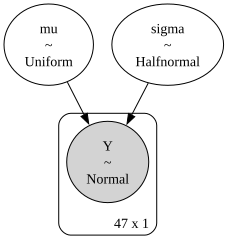

In [6]:
pm.model_to_graphviz(model)

### 4.2 Diagnóstico de Convergência MCMC (`az.plot_trace_dist`)
Avaliamos a qualidade da amostragem para $\mu$ e $\sigma$:
* **Densidades Marginais (esquerda):** As $4$ cadeias de $\mu$ (centradas em $\sim 53.6$) e de $\sigma$ (centradas em $\sim 3.5$, com leve assimetria à direita) estão perfeitamente sobrepostas.
* **Séries Temporais / *Traceplots* (direita):** Oscilação estacionária densa sem *drifts* ou travamentos, confirmando rápida convergência.

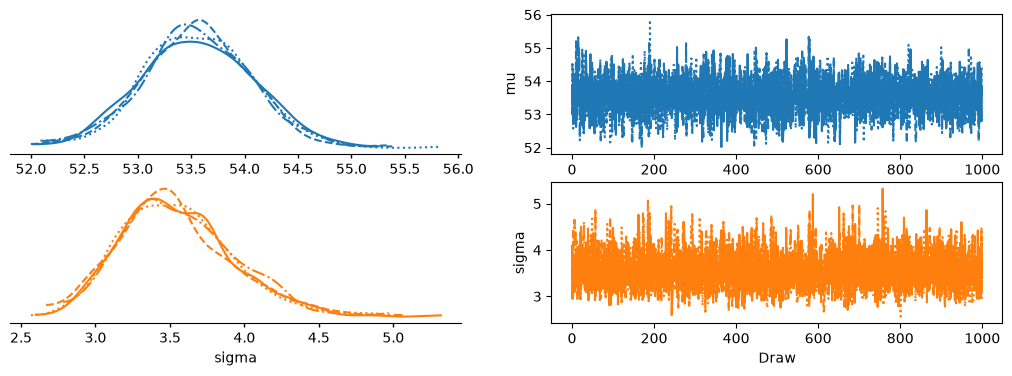

In [7]:
az.plot_trace_dist(idata)

### 4.3 Distribuição Conjunta *a Posteriori* (`az.plot_pair`)
O gráfico de pares (`plot_pair`) exibe as distribuições marginais 1D na diagonal e o contorno de densidade conjunta 2D $P(\mu, \sigma \mid Y)$ no painel inferior esquerdo:
* **Interpretação estatística:** Os contornos concêntricos têm formato aproximadamente circular/elíptico alinhado aos eixos, demonstrando que, no modelo Gaussiano, as estimativas *a posteriori* da média $\mu$ e do desvio-padrão $\sigma$ são **aproximadamente independentes** (não há correlação forte entre localização e escala).

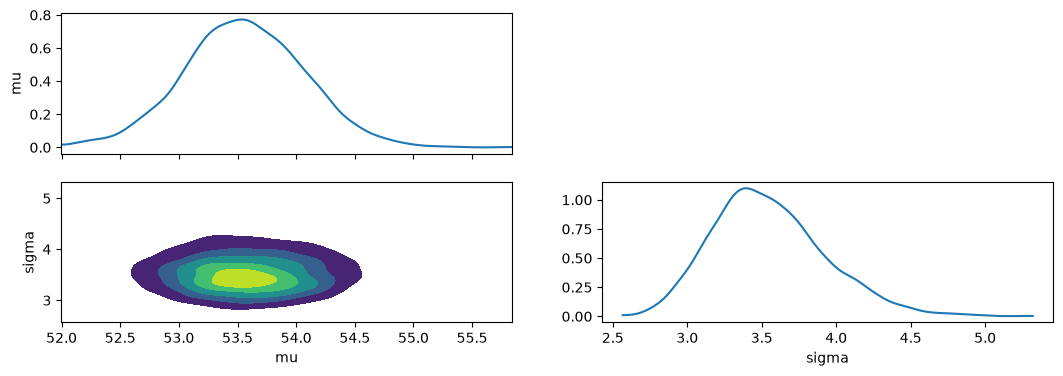

In [8]:
az.plot_pair(
    idata,
    var_names=['mu', 'sigma'],
    marginal=True,
    marginal_kind="kde",
    visuals={"contourf": True, "scatter": False},
    levels=5,  # opcional: número de faixas de contorno (ou lista, ex: [0.2, 0.4, 0.6, 0.8, 0.95])
)

### 4.4 Resumo Estatístico do Modelo Gaussiano (`az.summary`)
Analisando as estimativas *a posteriori* do modelo Normal:
* **`mu`:** Média de $\approx 53.6$ (arredondada para `54` com $2$ dígitos significativos), desvio-padrão `0.51` e **HDI 94% de `[53, 55]`**.
* **`sigma`:** Média de `3.5`, desvio-padrão `0.38` e **HDI 94% de `[2.9, 4.3]`**.
* **Atenção:** Esse valor de $\sigma = 3.5$ foi inflado pelos $2$ *outliers* presentes nos dados, o que ficará evidente na checagem preditiva a seguir.

In [9]:
az.summary(idata, kind='stats')

,mean,sd,hdi94_lb,hdi94_ub
mu,54,0.51,53,55
sigma,3.5,0.38,2.9,4.3


## 5. Checagem Preditiva *a Posteriori* (PPC) do Modelo Gaussiano

### 5.1 Geração das Amostras Preditivas (`pm.sample_posterior_predictive`)
Um bom modelo bayesiano não deve apenas convergir, mas também ser capaz de **gerar dados sintéticos semelhantes aos dados reais observados**. Calculamos a distribuição preditiva *a posteriori*:

$$P(\tilde{Y} \mid Y) = \iint P(\tilde{Y} \mid \mu, \sigma) \, P(\mu, \sigma \mid Y) \, d\mu \, d\sigma$$

Para cada par $(\mu^{(s)}, \sigma^{(s)})$ sorteado da *posterior*, simulamos um novo conjunto de $47$ observações $\tilde{Y}^{(s)}$, armazenado no grupo `posterior_predictive` do `idata`.

In [10]:
pm.sample_posterior_predictive(idata, model=model, extend_inferencedata=True)

Sampling: [Y]


Output()

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:  (chain: 4, draw: 1000)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│       Data variables:
│           mu       (chain, draw) float64 32kB 53.63 53.86 52.97 ... 54.25 53.38 53.8
│           sigma    (chain, draw) float64 32kB 4.084 2.947 3.124 ... 3.625 4.484 2.944
│       Attributes:
│           created_at:                 2026-11-08T21:50:42.880848+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.21116042137145996
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 2 2 2 2 1 ... 2 1 2 2 2
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 1.045 1.025 ... 1.005
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 1.084 1.084 ... 1.09
│           mean_tree_accept          (chain, draw) float64 32kB 0.886 0.9394 ... 1.0
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 0.001219 ... 0.05749
│           transformation_index      (chain, draw) int64 32kB 337 337 337 ... 337 337
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-11-08T21:50:42.854657+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Attributes:
│           created_at:                 2026-11-08T21:50:42.873471+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
├── Group: /observed_data
│       Dimensions:  (Y_dim_0: 47, Y_dim_1: 1)
│       Coordinates:
│         * Y_dim_0  (Y_dim_0) int64 376B 0 1 2 3 4 5 6 7 8 ... 39 40 41 42 43 44 45 46
│         * Y_dim_1  (Y_dim_1) int64 8B 0
│       Data variables:
│           Y        (Y_dim_0, Y_dim_1) float64 376B 55.12 53.73 50.24 ... 53.84 53.16
│       Attributes:
│           created_at:                 2026-11-08T21:50:44.347250+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
└── Group: /posterior_predictive
        Dimensions:  (chain: 4, draw: 1000, Y_dim_0: 47, Y_dim_1: 1)
  

### 5.2 Visualização do PPC Gaussiano (`az.plot_ppc_dist`)
Comparamos o histograma dos **dados reais observados (azul, `C0`)** com $100$ realizações da **distribuição preditiva simulada (laranja, `C1`)**:
* **Diagnóstico de falha de ajuste (*misfit*):** Duas observações isoladas na extrema direita (*outliers* acima de $60$) forçaram o modelo Gaussiano a aumentar artificialmente $\sigma$ (`3.5`) e deslocar $\mu$ para a direita. Como consequência, as previsões laranjas são **mais baixas no pico central e mais espalhadas** do que o corpo principal dos dados reais em azul.

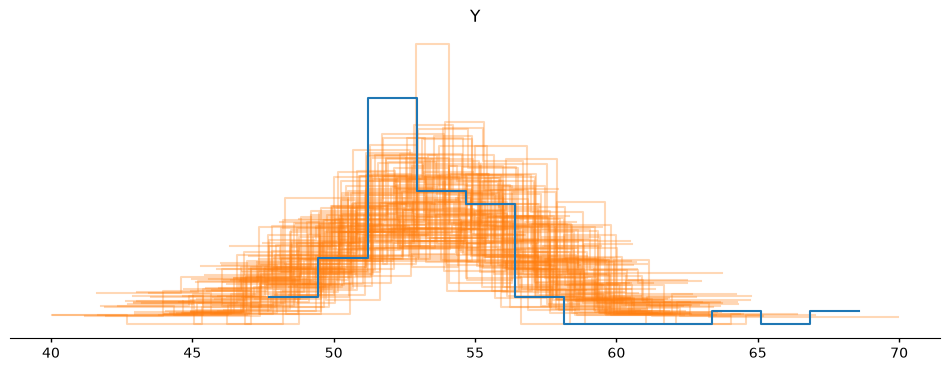

In [22]:
az.plot_ppc_dist(
    idata,
    kind='hist',
    num_samples=100,
    figure_kwargs={"figsize": (12, 4)},
    visuals={
        "predictive_dist": {"color": "C1"},  # curvas preditivas simuladas
        "observed_dist": {"color": "C0"},    # curva dos dados observados
    },
)

## 6. Modelo 2: Inferência Robusta com Distribuição t de Student (`model_t`)
Para tornar a inferência resistente a *outliers*, substituímos a verossimilhança Normal pela **distribuição t de Student**:

$$\begin{aligned}
\mu &\sim \text{Uniforme}(40, 75) \\
\sigma &\sim \text{HalfNormal}(\sigma = 70) \\
\nu &\sim \text{Exponencial}\!\left(\lambda = \frac{1}{30}\right) \\
y_i \mid \nu, \mu, \sigma &\stackrel{\text{i.i.d.}}{\sim} \text{StudentT}(\nu, \mu, \sigma), \quad i = 1, \dots, 47
\end{aligned}$$

* **Papel do parâmetro de normalidade $\nu$ (`v`):**
  * Controla o peso das caudas (*kurtosis*).
  * Se $\nu = 1$, temos uma distribuição de **Cauchy** (caudas extremamente pesadas).
  * Se $\nu \ge 30$, a distribuição t de Student converge na prática para uma **Normal**.
  * A *prior* $\nu \sim \text{Exponencial}(1/30)$ tem média igual a $30$ (não forçando caudas pesadas *a priori*), mas permite que a própria verossimilhança reduza $\nu$ caso existam *outliers*.

In [ ]:
with pm.Model() as model_t:
    mu = pm.Uniform('mu', lower=40, upper=75)
    sigma = pm.HalfNormal('sigma', sigma=70)
    v = pm.Exponential('v', 1/30)
    y = pm.StudentT('y', nu=v, mu=mu, sigma=sigma, observed=data)
    idata_t = pm.sample(nuts_sampler='nutpie', random_seed=4591)
    

NUTS[nutpie]: [mu, sigma, v]


Output()

### 6.1 Grafo Acíclico Direcionado (DAG) do Modelo Student-t
O grafo de `model_t` evidencia agora **três variáveis latentes** ($\mu \sim \text{Uniform}$, $\sigma \sim \text{HalfNormal}$ e $v \sim \text{Exponential}$) parametrizando a verossimilhança observada $y \sim \text{StudentT}$.

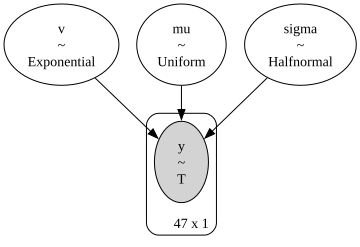

In [24]:
pm.model_to_graphviz(model_t)

### 6.2 Diagnóstico de Convergência do Modelo Student-t (`az.plot_trace_dist`)
As $4$ cadeias convergiram com ótima mistura para os três parâmetros:
* Observe que a distribuição *a posteriori* de **`v` ($\nu$)** concentrou-se em valores baixos (pico próximo a $3$–$4$), muito distante da média *a priori* de $30$, indicando que os dados demandam caudas pesadas.

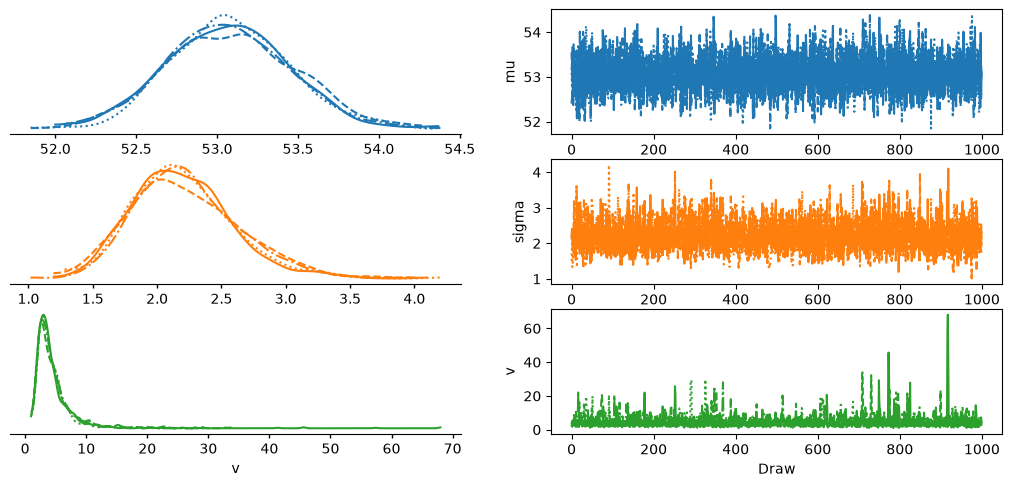

In [25]:
az.plot_trace_dist(idata_t)

### 6.3 Gráfico de Pares 3x3 (`az.plot_pair`) — Correlação entre $\sigma$ e $\nu$
Ao inspecionar a matriz de pares para `['mu', 'sigma', 'v']`:
* **$\mu$ vs. $(\sigma, \nu)$:** A localização central $\mu$ permanece descorrelacionada dos demais parâmetros.
* **$\sigma$ vs. $\nu$ (painel inferior central):** Existe uma **correlação positiva clara entre $\sigma$ e $\nu$**. Quando $\nu$ é menor (caudas mais pesadas), os *outliers* são explicados pelo formato da cauda, permitindo um parâmetro de escala $\sigma$ menor; quando $\nu$ cresce (aproximando-se da Normal), $\sigma$ precisa aumentar para acomodar os mesmos *outliers*.

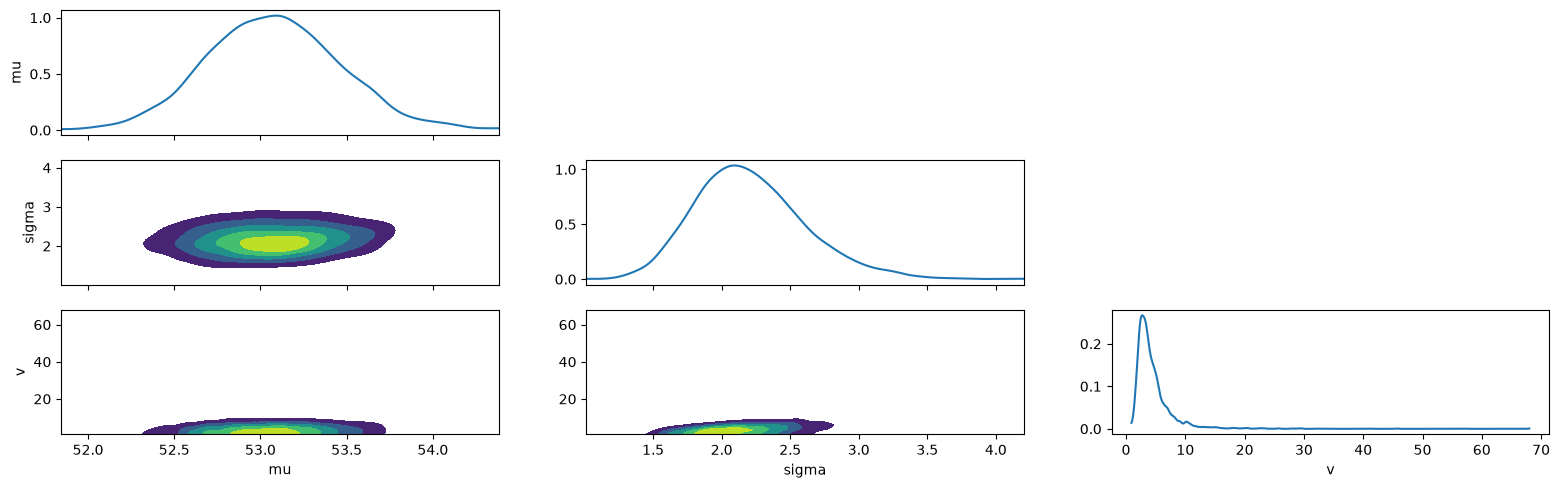

In [26]:
az.plot_pair(
    idata_t,
    var_names=['mu', 'sigma', 'v'],
    marginal=True,
    marginal_kind="kde",
    visuals={"contourf": True, "scatter": False},
    levels=5,  # opcional: número de faixas de contorno (ou lista, ex: [0.2, 0.4, 0.6, 0.8, 0.95])
)

### 6.4 Resumo Estatístico: Modelo Student-t vs. Modelo Gaussiano (`az.summary`)
Comparando os resultados do modelo robusto (`idata_t`) com o modelo Normal (`idata`):

| Parâmetro | Modelo Normal (`idata`) | Modelo Student-t (`idata_t`) | Conclusão Estatística |
| :--- | :---: | :---: | :--- |
| **`mu` ($\mu$)** | `53.56` (`sd = 0.51`, HDI `[53, 55]`) | **`53.0`** (`sd = 0.39`, HDI `[52, 54]`) | Estimativa central **mais precisa** (`sd` caiu de $0.51$ para $0.39$) e sem ser puxada para cima pelos $2$ *outliers*. |
| **`sigma` ($\sigma$)** | `3.50` (`sd = 0.38`, HDI `[2.9, 4.3]`) | **`2.20`** (`sd = 0.40`, HDI `[1.5, 3.0]`) | Redução expressiva da escala: $\sigma$ agora reflete a dispersão real das $45$ medições normais. |
| **`v` ($\nu$)** | $\infty$ (fixo na Normal) | **`4.60`** (`sd = 3.60`, HDI `[1.2, 9.4]`) | O HDI 94% de $\nu$ ($[1.2, 9.4]$) está inteiramente abaixo de $10$, confirmando estatisticamente a não-normalidade das caudas. |

In [28]:
az.summary(idata_t, kind='stats').round(2)

,mean,sd,hdi94_lb,hdi94_ub
mu,53,0.39,52,54
sigma,2.2,0.4,1.5,3
v,4.6,3.6,1.2,9.4


### 6.5 Amostragem Preditiva *a Posteriori* do Modelo Student-t
Geramos novos conjuntos de dados simulados a partir da posterior do modelo `model_t`.

In [30]:
pm.sample_posterior_predictive(idata_t, model=model_t, extend_inferencedata=True)

Sampling: [y]


Output()

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:  (chain: 4, draw: 1000)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│       Data variables:
│           mu       (chain, draw) float64 32kB 53.19 53.21 53.47 ... 52.51 53.28 52.94
│           sigma    (chain, draw) float64 32kB 2.143 2.41 2.045 ... 1.744 2.096 1.742
│           v        (chain, draw) float64 32kB 2.482 2.349 2.523 ... 3.237 4.254 4.072
│       Attributes:
│           created_at:                 2026-11-08T22:02:03.597898+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              0.1752605438232422
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 2 2 1 2 2 ... 2 2 2 3 1
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 0.875 0.9236 ... 0.7766
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 0.842 0.842 ... 0.8209
│           mean_tree_accept          (chain, draw) float64 32kB 1.0 0.8318 ... 0.7197
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 0.7204 1.369 ... 3.148
│           transformation_index      (chain, draw) int64 32kB 337 337 337 ... 338 338
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-11-08T22:02:03.580819+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Attributes:
│           created_at:                 2026-11-08T22:02:03.593209+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
├── Group: /observed_data
│       Dimensions:  (y_dim_0: 47, y_dim_1: 1)
│       Coordinates:
│         * y_dim_0  (y_dim_0) int64 376B 0 1 2 3 4 5 6 7 8 ... 39 40 41 42 43 44 45 46
│         * y_dim_1  (y_dim_1) int64 8B 0
│       Data variables:
│           y        (y_dim_0, y_dim_1) float64 376B 55.12 53.73 50.24 ... 53.84 53.16
│       Attributes:
│           created_at:                 2026-11-08T22:05:48.200558+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
└── Group:

### 6.6 Checagem Preditiva *a Posteriori* (PPC) do Modelo Student-t (`az.plot_ppc_dist`)
Comparando o PPC do modelo Student-t com o do modelo Gaussiano anterior:
* **Ajuste superior:** As curvas preditivas simuladas (laranja) agora acompanham fielmente a **altura do pico central** (entre $51$ e $55$ ppm) e a largura do corpo principal dos dados observados (azul), ao mesmo tempo em que suas caudas longas acomodam naturalmente valores extremos ocasionais.

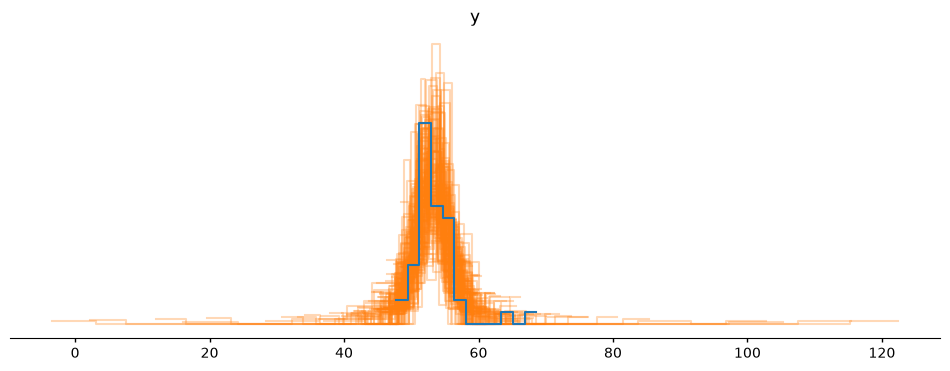

In [31]:
az.plot_ppc_dist(
    idata_t,
    kind='hist',
    num_samples=100,
    figure_kwargs={"figsize": (12, 4)},
    visuals={
        "predictive_dist": {"color": "C1"},  # curvas preditivas simuladas
        "observed_dist": {"color": "C0"},    # curva dos dados observados
    },
)

---

## 7. Manipulação e Inspeção da Posterior com `xarray.DataTree`
No PyMC `6.x` e ArviZ `1.x`, o objeto `idata` é estruturado como uma árvore hierárquica **`xarray.DataTree`**, permitindo indexação por coordenadas nomeadas (`chain`, `draw`) sem depender de índices posicionais frágeis de arrays NumPy.

### 7.1 Acesso ao Grupo `posterior`
Extraímos o nó `/posterior`, que armazena os tensores de amostras de `mu` e `sigma` nas dimensões `(chain: 4, draw: 1000)`.

In [32]:
posterior = idata.posterior

### 7.2 Filtragem por Coordenadas com `.sel()`
Selecionamos especificamente a primeira iteração (`draw=0`) das cadeias `0` e `2` (`chain=[0, 2]`):
* **Resultado:** Obtemos instantaneamente os valores amostrados naquele ponto exato (`mu = [53.63, 53.53]` e `sigma = [4.084, 4.09]`).

In [33]:
posterior.sel(draw=0, chain=[0, 2])

<xarray.DataTree 'posterior'>
Group: /
    Dimensions:  (chain: 2)
    Coordinates:
      * chain    (chain) int64 16B 0 2
        draw     int64 8B 0
    Data variables:
        mu       (chain) float64 16B 53.63 53.53
        sigma    (chain) float64 16B 4.084 4.09
    Attributes:
        created_at:                 2026-11-08T21:50:42.880848+00:00
        creation_library:           ArviZ
        creation_library_version:   1.3.0
        creation_library_language:  Python
        sample_dims:                ['chain', 'draw']
        inference_library:          nutpie
        inference_library_version:  0.16.11
        sampling_time:              0.21116042137145996
        tuning_steps:               400

### 7.3 Média Global *a Posteriori* (`posterior.mean()`)
Quando chamado sem argumentos, `.mean()` reduz **todas as dimensões de amostragem** (`chain` e `draw`, totalizando $4 \times 1000 = 4000$ amostras), retornando a esperança matemática *a posteriori* exata de cada parâmetro:
* $\mathbb{E}[\mu \mid Y] = 53.56$
* $\mathbb{E}[\sigma \mid Y] = 3.55$

In [34]:
posterior.mean()

<xarray.DataTree 'posterior'>
Group: /
    Dimensions:  ()
    Data variables:
        mu       float64 8B 53.56
        sigma    float64 8B 3.55
    Attributes:
        created_at:                 2026-11-08T21:50:42.880848+00:00
        creation_library:           ArviZ
        creation_library_version:   1.3.0
        creation_library_language:  Python
        sample_dims:                ['chain', 'draw']
        inference_library:          nutpie
        inference_library_version:  0.16.11
        sampling_time:              0.21116042137145996
        tuning_steps:               400

### 7.4 Média por Cadeia (`posterior.mean('draw')`)
Ao especificar a dimensão `'draw'`, calculamos a média ao longo das $1000$ iterações **separadamente para cada uma das $4$ cadeias**:
* **Resultado (`mu`: `53.56, 53.55, 53.57, 53.55` | `sigma`: `3.55, 3.533, 3.545, 3.572`):** A proximidade na segunda casa decimal entre as $4$ cadeias independentes é uma confirmação numérica direta da estacionariedade e convergência do MCMC.

In [35]:
posterior.mean('draw')

<xarray.DataTree 'posterior'>
Group: /
    Dimensions:  (chain: 4)
    Coordinates:
      * chain    (chain) int64 32B 0 1 2 3
    Data variables:
        mu       (chain) float64 32B 53.56 53.55 53.57 53.55
        sigma    (chain) float64 32B 3.55 3.533 3.545 3.572
    Attributes:
        created_at:                 2026-11-08T21:50:42.880848+00:00
        creation_library:           ArviZ
        creation_library_version:   1.3.0
        creation_library_language:  Python
        sample_dims:                ['chain', 'draw']
        inference_library:          nutpie
        inference_library_version:  0.16.11
        sampling_time:              0.21116042137145996
        tuning_steps:               400

### 7.5 Empilhamento de Cadeias e Amostras com `az.extract(idata)`
Para cálculos vetorizados a jusante (como funções de perda customizadas ou transformações não-lineares), frequentemente desejamos combinar as dimensões `(chain: 4, draw: 1000)` em uma única dimensão linear de amostras `(sample: 4000)`. A função `az.extract(idata)` realiza esse *stacking* preservando o `MultiIndex` original de cadeia e iteração.

In [37]:
stacked = az.extract(idata)
stacked

<xarray.Dataset> Size: 160kB
Dimensions:  (sample: 4000)
Coordinates:
  * sample   (sample) object 32kB MultiIndex
  * chain    (sample) int64 32kB 0 0 0 0 0 0 0 0 0 0 0 ... 3 3 3 3 3 3 3 3 3 3 3
  * draw     (sample) int64 32kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
Data variables:
    mu       (sample) float64 32kB 53.63 53.86 52.97 54.14 ... 54.25 53.38 53.8
    sigma    (sample) float64 32kB 4.084 2.947 3.124 3.3 ... 3.625 4.484 2.944
Attributes:
    created_at:                 2026-11-08T21:50:42.880848+00:00
    creation_library:           ArviZ
    creation_library_version:   1.3.0
    creation_library_language:  Python
    sample_dims:                ['sample']
    inference_library:          nutpie
    inference_library_version:  0.16.11
    sampling_time:              0.21116042137145996
    tuning_steps:               400